# Laboratorio guiado y didáctico: análisis exploratorio de datos (EDA)

**PUCE Ambato · Duración total: 3 horas · Caso: rendimiento académico**

En este laboratorio aprenderás a transformar un archivo CSV en conclusiones prudentes y respaldadas por evidencia. No se trata solamente de ejecutar Python: en cada paso encontrarás **qué haremos, por qué lo hacemos, cómo leer el resultado y una actividad breve**.

> **Pregunta central:** ¿qué patrones de participación, uso de recursos y ausencias aparecen asociados con el nivel de rendimiento?

**Producto final:** dos visualizaciones y tres hallazgos que incluyan evidencia, una limitación y una recomendación responsable.


## Cómo utilizar este cuaderno

1. Ejecuta las celdas en orden con <kbd>Shift</kbd> + <kbd>Enter</kbd>.
2. Lee la explicación **antes** de ejecutar el código.
3. Después de cada resultado, responde la pregunta de interpretación.
4. Usa las respuestas desplegables solo después de intentarlo.

| Señal | Significado |
|---|---|
| 🎯 | Objetivo del paso |
| ▶️ | Acción que debes realizar |
| 👀 | Elementos que debes observar |
| ✍️ | Respuesta o actividad del estudiante |
| ⚠️ | Precaución al interpretar |

### Ruta de 180 minutos

| Etapa | Tiempo |
|---|---:|
| 0. Preparar el entorno y comprender EDA | 10 min |
| 1. Cargar y conocer los datos | 20 min |
| 2. Evaluar la calidad | 20 min |
| 3. Resumir con estadística descriptiva | 20 min |
| 4. Analizar una variable | 20 min |
| 5. Comparar variables | 25 min |
| 6. Estudiar ausencias y rendimiento | 15 min |
| 7. Explorar correlaciones | 15 min |
| 8. Resolver y comunicar el reto | 25 min |
| 9. Cerrar y autoevaluarse | 10 min |


## Antes de comenzar: ¿qué es EDA?

El **análisis exploratorio de datos (EDA)** es un proceso para conocer los datos antes de construir un modelo o tomar una decisión. Combina preguntas, revisión de calidad, cálculos, gráficos e interpretación.

Durante un EDA buscamos:

- comprender la estructura del conjunto de datos;
- identificar errores, ausencias o valores inusuales;
- resumir distribuciones y comparar grupos;
- detectar patrones que generen nuevas preguntas;
- comunicar lo que los datos muestran **y lo que todavía no permiten afirmar**.

> ⚠️ Encontrar una asociación no demuestra una relación de causa y efecto.


## 0. Preparar el entorno (10 min)

### Paso 0.1 · Importar las bibliotecas

🎯 **Propósito:** cargar herramientas ya creadas para trabajar con tablas, cálculos y gráficos.

- <code>pandas</code>: organiza los datos en tablas llamadas DataFrames.
- <code>numpy</code>: ofrece operaciones numéricas.
- <code>matplotlib</code>: crea y personaliza gráficos.
- <code>seaborn</code>: facilita visualizaciones estadísticas.
- La instrucción <code>as</code> crea un alias corto, por ejemplo <code>pd</code> para <code>pandas</code>.

▶️ Ejecuta la siguiente celda. Si aparece <code>ModuleNotFoundError</code>, ejecuta primero: <code>%pip install pandas numpy matplotlib seaborn</code>.


In [1]:
# Importamos las bibliotecas que utilizaremos durante el laboratorio.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Definimos una identidad visual consistente con los tonos azules de PUCE.
AZUL_PUCE = "#003DA5"
CELESTE = "#00A6D6"
CORAL = "#F56B5D"
VERDE = "#248F73"

# Aplicamos un estilo limpio a todos los gráficos del cuaderno.
sns.set_theme(style="whitegrid", context="notebook")

print("✓ Bibliotecas cargadas correctamente")
print("Versión de pandas:", pd.__version__)


✓ Bibliotecas cargadas correctamente
Versión de pandas: 2.3.3


👀 **Cómo leer el resultado:** debes ver dos líneas y ninguna advertencia en rojo. La primera confirma que las importaciones funcionaron; la segunda muestra la versión de pandas disponible.

<details>
<summary><strong>Comprueba tu comprensión</strong></summary>

¿Por qué usamos alias? Porque permiten escribir instrucciones más breves y siguen convenciones reconocidas por la comunidad de Python; por ejemplo, <code>pd.read_csv()</code> en lugar de <code>pandas.read_csv()</code>.
</details>


## 1. Cargar y conocer los datos (20 min)

### Paso 1.1 · Localizar el archivo CSV

🎯 **Propósito:** indicarle a Python dónde se encuentra el archivo <code>xAPI-Edu-Data.csv</code>.

Un objeto <code>Path</code> representa una ruta. <code>Path.cwd()</code> informa la carpeta desde la que se está ejecutando el cuaderno. El código buscará el CSV en la carpeta actual y junto al notebook.

▶️ Guarda el CSV en la misma carpeta que este cuaderno y ejecuta la celda.


In [2]:
# Nombre esperado del archivo de datos.
nombre_archivo = "xAPI-Edu-Data.csv"

# Buscamos el archivo en la carpeta de trabajo actual.
ruta = Path(nombre_archivo)

print("Carpeta de trabajo:", Path.cwd())
print("Archivo buscado:", ruta.resolve())

# Si no existe, detenemos el proceso con un mensaje útil.
if not ruta.exists():
    raise FileNotFoundError(
        f"No se encontró {nombre_archivo}. "
        "Colócalo en la misma carpeta del notebook y vuelve a ejecutar."
    )

print("✓ Archivo localizado")


Carpeta de trabajo: c:\PUCESA_PROGRAMACION2\Programacion materia Inteligencia Artificial\RDA2
Archivo buscado: C:\PUCESA_PROGRAMACION2\Programacion materia Inteligencia Artificial\RDA2\xAPI-Edu-Data.csv
✓ Archivo localizado


👀 **Qué observar:** la ruta mostrada debe terminar en <code>xAPI-Edu-Data.csv</code> y aparecerá el mensaje “Archivo localizado”. Si recibes un error, revisa el nombre exacto, la extensión y la carpeta.

### Paso 1.2 · Leer el CSV como un DataFrame

🎯 <code>pd.read_csv()</code> interpreta las filas y columnas del archivo y devuelve una tabla. Guardamos esa tabla en la variable <code>df</code>, abreviatura habitual de DataFrame.


In [3]:
# Leemos el archivo y guardamos la tabla en la variable df.
df = pd.read_csv(ruta)

# Confirmamos que la carga terminó.
print("✓ Datos cargados en el DataFrame 'df'")


✓ Datos cargados en el DataFrame 'df'


### Paso 1.3 · Mirar las primeras filas

🎯 <code>head(n)</code> muestra las primeras <code>n</code> filas. Sirve para verificar si los encabezados y valores se interpretaron correctamente.

▶️ No intentes concluir todavía; primero familiarízate con la tabla.


In [4]:
# Mostramos las primeras cinco observaciones.
display(df.head(5))


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


👀 **Qué observar:** cada fila representa un registro de estudiante y cada columna una característica. Busca variables de contexto, interacción y resultado.

### Paso 1.4 · Conocer el tamaño

🎯 El atributo <code>shape</code> devuelve una tupla con el formato <code>(filas, columnas)</code>. No lleva paréntesis porque es un atributo, no una función.


In [5]:
# Separamos las dos dimensiones para que la lectura sea explícita.
numero_filas, numero_columnas = df.shape

print("Número de filas:", numero_filas)
print("Número de columnas:", numero_columnas)


Número de filas: 480
Número de columnas: 17


<details>
<summary><strong>Respuesta esperada con el archivo original</strong></summary>

El conjunto contiene **480 filas y 17 columnas**. Si obtienes otro tamaño, verifica que estés usando el archivo correcto o documenta cualquier transformación previa.
</details>

### Paso 1.5 · Revisar tipos y valores no nulos

🎯 <code>info()</code> resume el tipo de cada variable y cuántos valores no nulos posee. <code>int64</code> indica números enteros y <code>object</code> suele representar texto o categorías.


In [6]:
# info() imprime un resumen estructural del DataFrame.
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   gender                    480 non-null    object
 1   NationalITy               480 non-null    object
 2   PlaceofBirth              480 non-null    object
 3   StageID                   480 non-null    object
 4   GradeID                   480 non-null    object
 5   SectionID                 480 non-null    object
 6   Topic                     480 non-null    object
 7   Semester                  480 non-null    object
 8   Relation                  480 non-null    object
 9   raisedhands               480 non-null    int64 
 10  VisITedResources          480 non-null    int64 
 11  AnnouncementsView         480 non-null    int64 
 12  Discussion                480 non-null    int64 
 13  ParentAnsweringSurvey     480 non-null    object
 14  ParentschoolSatisfaction  

👀 **Cómo interpretarlo:** compara el número de valores “Non-Null” con las 480 filas. Si una columna tiene menos valores no nulos que filas, contiene datos faltantes.

### Paso 1.6 · Comprender las variables

La variable objetivo es <code>Class</code>:

- <code>L</code>: rendimiento bajo;
- <code>M</code>: rendimiento medio;
- <code>H</code>: rendimiento alto.

Las variables <code>raisedhands</code>, <code>VisITedResources</code>, <code>AnnouncementsView</code> y <code>Discussion</code> describen interacciones del estudiante. No son calificaciones directas.


In [7]:
# Creamos un diccionario breve para no interpretar nombres sin contexto.
diccionario = pd.DataFrame({
    "Variable": [
        "gender", "NationalITy", "PlaceofBirth", "StageID", "GradeID",
        "SectionID", "Topic", "Semester", "Relation", "raisedhands",
        "VisITedResources", "AnnouncementsView", "Discussion",
        "ParentAnsweringSurvey", "ParentschoolSatisfaction",
        "StudentAbsenceDays", "Class"
    ],
    "Descripción breve": [
        "Género registrado", "Nacionalidad", "Lugar de nacimiento",
        "Etapa educativa", "Grado", "Sección", "Asignatura",
        "Semestre", "Responsable relacionado", "Veces que levantó la mano",
        "Visitas a recursos", "Vistas de anuncios", "Participación en discusión",
        "Respuesta del representante a encuestas", "Satisfacción del representante",
        "Categoría de días de ausencia", "Nivel de rendimiento: L, M o H"
    ]
})

display(diccionario)


,Variable,Descripción breve
0,gender,Género registrado
1,NationalITy,Nacionalidad
2,PlaceofBirth,Lugar de nacimiento
3,StageID,Etapa educativa
4,GradeID,Grado
5,SectionID,Sección
6,Topic,Asignatura
7,Semester,Semestre
8,Relation,Responsable relacionado
9,raisedhands,Veces que levantó la mano



✍️ **Pausa didáctica:** escribe una pregunta que pueda responderse con estas variables.

> Mi pregunta: Cual es la relacion entre el rendimiento y levantar la mano?

<details>
<summary><strong>Ejemplos de preguntas investigables</strong></summary>

- ¿Cómo cambia la participación entre los niveles de rendimiento?
- ¿Cómo se distribuye el rendimiento según la categoría de ausencias?
- ¿Existe una relación lineal entre levantar la mano y visitar recursos?
</details>


## 2. Evaluar la calidad de los datos (20 min)

### Paso 2.1 · Construir un informe de calidad

🎯 Antes de calcular o graficar debemos comprobar si los datos son utilizables. Revisaremos:

- el tipo de cada columna;
- valores faltantes;
- cantidad de valores distintos;
- filas exactamente duplicadas;
- rangos imposibles en variables numéricas.

⚠️ Un cero puede ser una observación válida. No debe convertirse en nulo sin conocer su significado.


In [8]:
# Creamos una tabla de diagnóstico, una fila por variable.
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_%": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=False)
})

display(calidad)


,tipo,nulos,nulos_%,valores_unicos
gender,object,0,0.0,2
NationalITy,object,0,0.0,14
PlaceofBirth,object,0,0.0,14
StageID,object,0,0.0,3
GradeID,object,0,0.0,10
SectionID,object,0,0.0,3
Topic,object,0,0.0,12
Semester,object,0,0.0,2
Relation,object,0,0.0,2
raisedhands,int64,0,0.0,82


👀 **Cómo leerla:**

- <code>nulos</code> cuenta celdas vacías;
- <code>nulos_%</code> permite comparar columnas aunque tengan distinto tamaño;
- <code>valores_unicos</code> ayuda a detectar categorías inesperadas o identificadores.

<details>
<summary><strong>Respuesta esperada con el archivo original</strong></summary>

No hay valores faltantes. Esto no garantiza que todos los valores sean correctos: todavía debemos revisar duplicados, categorías y rangos.
</details>

### Paso 2.2 · Detectar filas duplicadas

🎯 <code>duplicated()</code> marca como <code>True</code> las filas idénticas a una anterior. El método no decide si son errores; esa decisión requiere contexto.


In [9]:
# Contamos las filas que repiten exactamente todos sus valores.
numero_duplicados = int(df.duplicated().sum())
print("Filas exactamente duplicadas:", numero_duplicados)

# Si existen, las mostramos para poder investigarlas.
if numero_duplicados > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)))
else:
    print("No se encontraron duplicados exactos.")


Filas exactamente duplicadas: 2


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
322,M,Jordan,Jordan,lowerlevel,G-02,A,French,F,Father,10,15,10,21,No,Bad,Above-7,L
326,M,Jordan,Jordan,lowerlevel,G-02,A,French,F,Father,10,15,10,21,No,Bad,Above-7,L
323,M,Jordan,Jordan,lowerlevel,G-02,A,French,S,Father,30,10,20,5,No,Bad,Above-7,L
327,M,Jordan,Jordan,lowerlevel,G-02,A,French,S,Father,30,10,20,5,No,Bad,Above-7,L


👀 **Qué observar:** con el archivo original aparecen **2 filas marcadas como duplicadas**. Esto no demuestra que sean errores: podrían representar estudiantes distintos con las mismas respuestas si no existe un identificador único.

⚠️ **Decisión responsable:** no las eliminaremos automáticamente. Primero documentamos el hallazgo y preguntamos cómo se generó el conjunto de datos.

### Paso 2.3 · Validar rangos y categorías

🎯 Una regla de dominio expresa qué valores son plausibles. Las cuatro variables de interacción deberían estar entre 0 y 100; <code>Class</code> debería contener solo L, M y H.


In [26]:
# Variables que, según la documentación del caso, usan una escala de 0 a 100.
variables_0_100 = [
    "raisedhands", "VisITedResources", "AnnouncementsView", "Discussion"
]

# Contamos cuántos valores caen fuera del intervalo permitido.
fuera_de_rango = {
    columna: int((~df[columna].between(0, 100)).sum())
    for columna in variables_0_100
}

# Revisamos también las categorías de la variable objetivo.
clases_esperadas = {"L", "M", "H"}
clases_encontradas = set(df["Class"].dropna().unique())

print("Valores fuera de 0–100:", fuera_de_rango)
print("Categorías encontradas en Class:", sorted(clases_encontradas))
print("Categorías inesperadas:", sorted(clases_encontradas - clases_esperadas))


Valores fuera de 0–100: {'raisedhands': 0, 'VisITedResources': 0, 'AnnouncementsView': 0, 'Discussion': 0}
Categorías encontradas en Class: ['H', 'L', 'M']
Categorías inesperadas: []


✍️ **Decisión de calidad:** completa la frase.

> Antes de eliminar o corregir un dato, debo __________________________________________ porque __________________________________________.

<details>
<summary><strong>Una respuesta razonable</strong></summary>

Antes de eliminar o corregir un dato, debo revisar la documentación o consultar al responsable de los datos, porque un valor inusual no es necesariamente un error.
</details>


## 3. Resumir con estadística descriptiva (20 min)

### Paso 3.1 · Separar variables numéricas y categóricas

🎯 No todas las variables se resumen de la misma manera. Para números interesan medidas como media, mediana y cuartiles; para categorías interesan frecuencias y proporciones.


In [27]:
# select_dtypes permite seleccionar columnas según su tipo.
columnas_numericas = df.select_dtypes(include="number").columns.tolist()
columnas_categoricas = df.select_dtypes(exclude="number").columns.tolist()

print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)


Variables numéricas: ['raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion']
Variables categóricas: ['gender', 'NationalITy', 'PlaceofBirth', 'StageID', 'GradeID', 'SectionID', 'Topic', 'Semester', 'Relation', 'ParentAnsweringSurvey', 'ParentschoolSatisfaction', 'StudentAbsenceDays', 'Class']


### Paso 3.2 · Resumir las variables numéricas

🎯 <code>describe()</code> calcula cantidad, media, desviación estándar, mínimo, cuartiles y máximo.

- **Media:** promedio aritmético; es sensible a valores extremos.
- **Mediana:** valor central; suele ser más resistente a extremos.
- **Q1 y Q3:** delimitan el 50 % central de los datos.


In [12]:
# Transponemos el resultado para que cada variable aparezca como una fila.
resumen_numerico = df[columnas_numericas].describe().T
display(resumen_numerico.round(2))


,count,mean,std,min,25%,50%,75%,max
raisedhands,480.0,46.78,30.78,0.0,15.75,50.0,75.0,100.0
VisITedResources,480.0,54.80,33.08,0.0,20.00,65.0,84.0,99.0
AnnouncementsView,480.0,37.92,26.61,0.0,14.00,33.0,58.0,98.0
Discussion,480.0,43.28,27.64,1.0,20.00,39.0,70.0,99.0


### Paso 3.3 · Comparar media y mediana

🎯 Una diferencia visible entre media y mediana puede sugerir asimetría o valores extremos. Es una señal para mirar la distribución; no es una prueba suficiente por sí sola.


In [13]:
# Calculamos ambas medidas para las variables de interacción.
comparacion_centro = pd.DataFrame({
    "media": df[variables_0_100].mean(),
    "mediana": df[variables_0_100].median()
})

comparacion_centro["diferencia_absoluta"] = (
    comparacion_centro["media"] - comparacion_centro["mediana"]
).abs()

display(comparacion_centro.round(2).sort_values("diferencia_absoluta", ascending=False))


,media,mediana,diferencia_absoluta
VisITedResources,54.80,65.0,10.20
AnnouncementsView,37.92,33.0,4.92
Discussion,43.28,39.0,4.28
raisedhands,46.78,50.0,3.23


👀 **Cómo interpretar:** comienza por la variable con mayor diferencia absoluta. Después revisa su histograma; no concluyas “hay valores erróneos” únicamente por esta diferencia.

### Paso 3.4 · Resumir la variable objetivo

🎯 <code>value_counts()</code> cuenta cuántas observaciones pertenecen a cada categoría. Con <code>normalize=True</code> obtiene proporciones.


In [14]:
# Definimos un orden lógico: bajo, medio y alto.
orden_clase = ["L", "M", "H"]

frecuencia_clase = df["Class"].value_counts().reindex(orden_clase)
porcentaje_clase = (
    df["Class"].value_counts(normalize=True).reindex(orden_clase) * 100
).round(1)

resumen_clase = pd.DataFrame({
    "frecuencia": frecuencia_clase,
    "porcentaje": porcentaje_clase
})

display(resumen_clase)


,frecuencia,porcentaje
Class,,
L,127,26.5
M,211,44.0
H,142,29.6


<details>
<summary><strong>Respuesta esperada con el archivo original</strong></summary>

La categoría media (M) es la más frecuente: **211 registros, aproximadamente 44,0 %**. Describe composición, no explica por qué un estudiante pertenece a una categoría.
</details>


## 4. Analizar una variable (20 min)

### Paso 4.1 · Gráfico de barras para una variable categórica

🎯 Un gráfico de barras compara frecuencias entre categorías. La longitud de la barra representa el número de registros.

▶️ Observa el orden de las categorías y las etiquetas sobre cada barra.


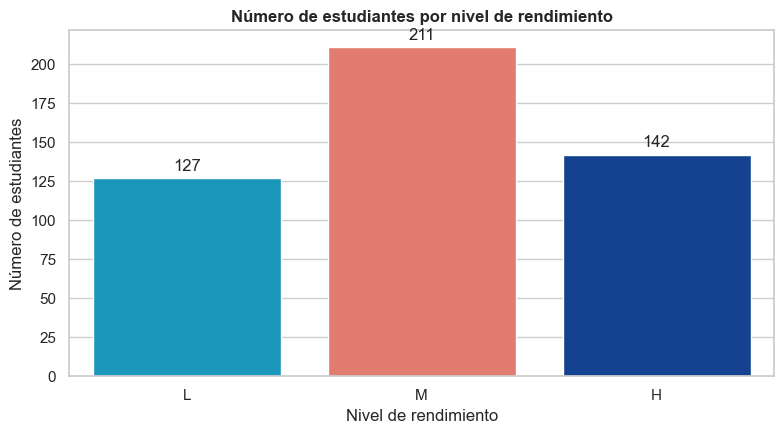

In [26]:
# Creamos el lienzo donde se dibujará el gráfico.
plt.figure(figsize=(8, 4.5))

# countplot cuenta y representa las categorías de Class.
ax = sns.countplot(
    data=df,
    x="Class",
    order=orden_clase,
    palette=[CORAL, CELESTE, AZUL_PUCE],
    hue="Class",
    legend=False
)

# Añadimos títulos y etiquetas comprensibles.
ax.set_title("Número de estudiantes por nivel de rendimiento", weight="bold")
ax.set_xlabel("Nivel de rendimiento")
ax.set_ylabel("Número de estudiantes")

# Escribimos la frecuencia encima de cada barra.
for contenedor in ax.containers:
    ax.bar_label(contenedor, padding=3)

plt.tight_layout()
plt.show()


👀 **Lectura correcta:** primero describe qué categoría es más o menos frecuente. Después cuantifica la diferencia. Evita explicaciones causales que el gráfico no demuestra.

✍️ **Escribe un hallazgo descriptivo:**

> La categoría __________ reúne __________ registros, equivalentes al __________ % del conjunto.

### Paso 4.2 · Histograma para una variable numérica

🎯 Un histograma divide una variable numérica en intervalos y muestra cuántos valores caen en cada uno. A diferencia del gráfico de barras, representa una escala numérica continua o discreta.


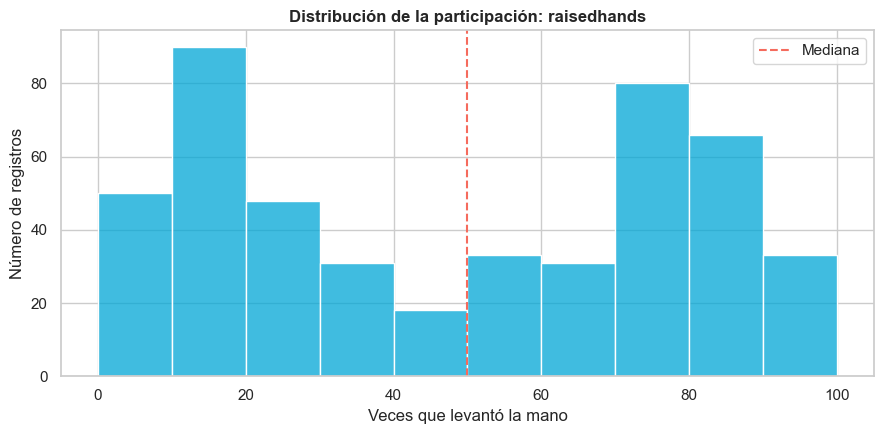

In [29]:
plt.figure(figsize=(9, 4.5))

# bins=10 divide la escala en diez intervalos.
ax = sns.histplot(
    data=df,
    x="raisedhands",
    bins=10,
    color=CELESTE,
    edgecolor="white"
)

ax.axvline(df["raisedhands"].median(), color=CORAL, linestyle="--", label="Mediana")
ax.set_title("Distribución de la participación: raisedhands", weight="bold")
ax.set_xlabel("Veces que levantó la mano")
ax.set_ylabel("Número de registros")
ax.legend()

plt.tight_layout()
plt.show()


👀 **Busca cuatro elementos:** concentración, vacíos, asimetría y valores alejados. La línea punteada señala la mediana.

### Paso 4.3 · Comprobar el efecto de los intervalos

🎯 El aspecto de un histograma cambia con <code>bins</code>. Probar varias opciones evita depender de una sola partición visual.


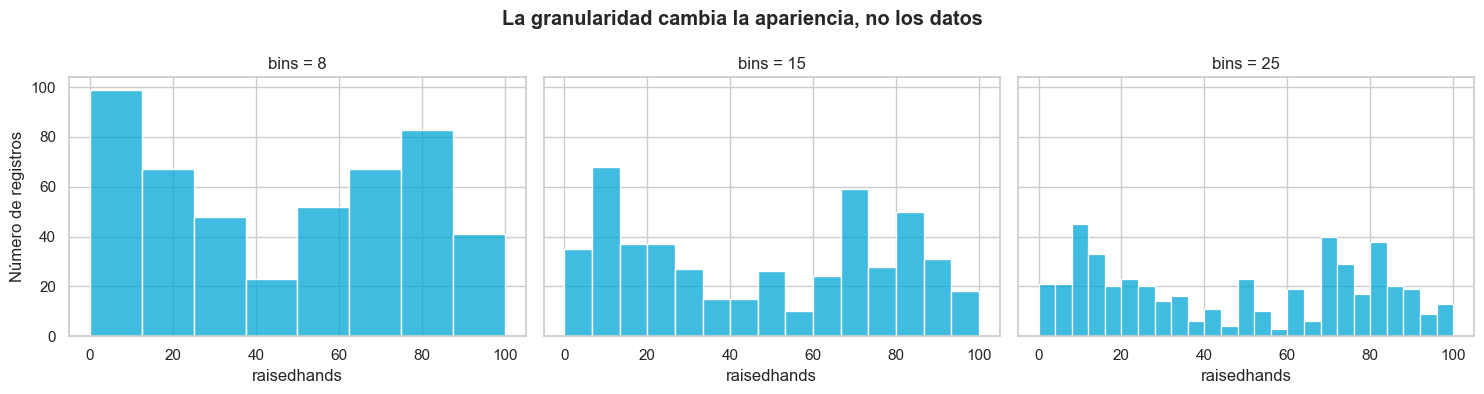

In [30]:
# Comparamos exactamente los mismos datos con distinta granularidad.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, numero_bins in zip(axes, [8, 15, 25]):
    sns.histplot(df["raisedhands"], bins=numero_bins, color=CELESTE, ax=ax)
    ax.set_title(f"bins = {numero_bins}")
    ax.set_xlabel("raisedhands")

axes[0].set_ylabel("Número de registros")
fig.suptitle("La granularidad cambia la apariencia, no los datos", weight="bold")
plt.tight_layout()
plt.show()


✍️ **Reflexión:** ¿qué patrón se mantiene en los tres gráficos y qué detalle cambia?

<details>
<summary><strong>Pista de interpretación</strong></summary>

Los valores originales son los mismos. Al aumentar <code>bins</code> se observan más detalles, pero también más irregularidad; con menos intervalos la forma se simplifica.
</details>


## 5. Comparar variables (25 min)

### Paso 5.1 · Comparar participación entre niveles

🎯 Un boxplot resume una variable numérica dentro de cada categoría. La línea central es la mediana, la caja abarca de Q1 a Q3, los “bigotes” muestran la extensión habitual y los puntos aislados invitan a investigar.

⚠️ Un punto aislado no se elimina automáticamente.


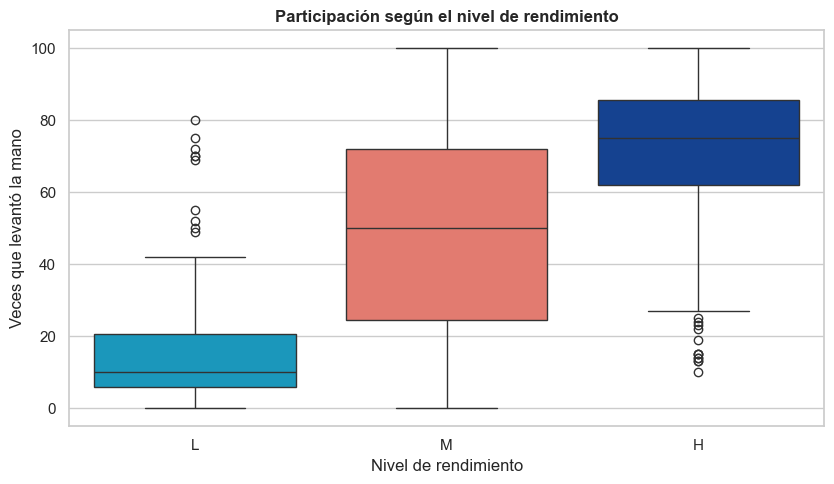

In [31]:
plt.figure(figsize=(8.5, 5))

ax = sns.boxplot(
    data=df,
    x="Class",
    y="raisedhands",
    order=orden_clase,
    palette=[CORAL, CELESTE, AZUL_PUCE],
    hue="Class",
    legend=False
)

ax.set_title("Participación según el nivel de rendimiento", weight="bold")
ax.set_xlabel("Nivel de rendimiento")
ax.set_ylabel("Veces que levantó la mano")

plt.tight_layout()
plt.show()


### Paso 5.2 · Confirmar el gráfico con una tabla

🎯 La visualización permite detectar un patrón; la tabla aporta valores exactos. Usar ambas reduce interpretaciones vagas.


In [32]:
# Calculamos los cinco números que ayudan a leer cada boxplot.
resumen_por_clase = df.groupby("Class", observed=False)["raisedhands"].agg(
    minimo="min",
    Q1=lambda serie: serie.quantile(0.25),
    mediana="median",
    Q3=lambda serie: serie.quantile(0.75),
    maximo="max",
    cantidad="size"
).reindex(orden_clase)

display(resumen_por_clase.round(1))


,minimo,Q1,mediana,Q3,maximo,cantidad
Class,,,,,,
L,0,6.0,10.0,20.5,80,127
M,0,24.5,50.0,72.0,100,211
H,10,62.0,75.0,85.8,100,142


<details>
<summary><strong>Lectura orientativa con el archivo original</strong></summary>

Las medianas de <code>raisedhands</code> aumentan de **10 en L**, a **50 en M** y **75 en H**. Esto muestra una asociación entre las variables en este conjunto, pero no prueba que levantar la mano cause el rendimiento.
</details>

### Paso 5.3 · Explorar la relación entre dos variables numéricas

🎯 Un diagrama de dispersión representa cada fila como un punto. La posición horizontal corresponde a <code>raisedhands</code> y la vertical a <code>VisITedResources</code>. El color identifica <code>Class</code>.


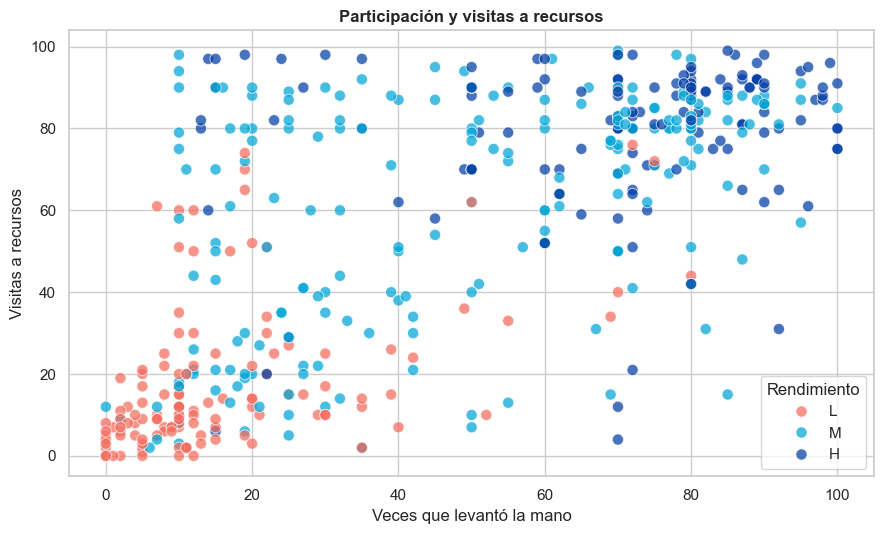

In [33]:
plt.figure(figsize=(9, 5.5))

ax = sns.scatterplot(
    data=df,
    x="raisedhands",
    y="VisITedResources",
    hue="Class",
    hue_order=orden_clase,
    palette=[CORAL, CELESTE, AZUL_PUCE],
    alpha=0.72,
    s=65
)

ax.set_title("Participación y visitas a recursos", weight="bold")
ax.set_xlabel("Veces que levantó la mano")
ax.set_ylabel("Visitas a recursos")
ax.legend(title="Rendimiento")

plt.tight_layout()
plt.show()


👀 **Cómo leerlo:**

- una nube ascendente sugiere relación positiva;
- una nube descendente sugiere relación negativa;
- una nube sin dirección clara sugiere relación lineal débil;
- la superposición de colores recuerda que una variable no determina por sí sola la categoría.

✍️ **Pregunta:** ¿hay una tendencia general? ¿Existen excepciones? Escribe ambas cosas para no simplificar demasiado el resultado.


## 6. Estudiar ausencias y rendimiento (15 min)

### Paso 6.1 · Crear una tabla cruzada

🎯 <code>pd.crosstab()</code> cruza dos variables categóricas. Con <code>normalize="index"</code> cada fila suma 100 %, lo que permite comparar grupos aunque tengan distinto tamaño.


In [34]:
# Calculamos porcentajes dentro de cada categoría de ausencias.
tabla_ausencias = pd.crosstab(
    df["StudentAbsenceDays"],
    df["Class"],
    normalize="index"
).reindex(columns=orden_clase).mul(100).round(1)

display(tabla_ausencias)

# Verificamos que cada fila sume aproximadamente 100 %.
print("Suma por fila:")
display(tabla_ausencias.sum(axis=1))


Class,L,M,H
StudentAbsenceDays,,,
Above-7,60.7,37.2,2.1
Under-7,3.8,48.4,47.8


Suma por fila:


StudentAbsenceDays
Above-7    100.0
Under-7    100.0
dtype: float64

### Paso 6.2 · Representar porcentajes apilados

🎯 Una barra apilada al 100 % muestra la composición interna de cada grupo de ausencias.


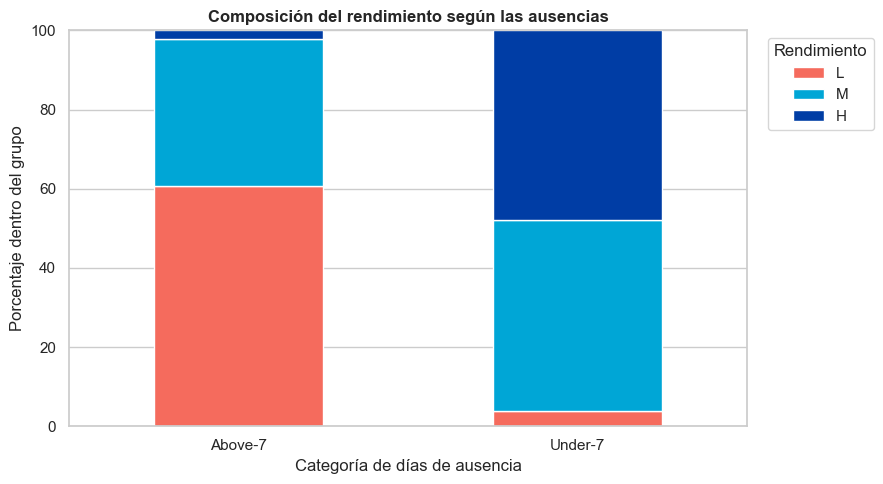

In [35]:
ax = tabla_ausencias.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=[CORAL, CELESTE, AZUL_PUCE]
)

ax.set_title("Composición del rendimiento según las ausencias", weight="bold")
ax.set_xlabel("Categoría de días de ausencia")
ax.set_ylabel("Porcentaje dentro del grupo")
ax.set_ylim(0, 100)
ax.legend(title="Rendimiento", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


<details>
<summary><strong>Lectura orientativa con el archivo original</strong></summary>

Entre quienes registran menos de siete días de ausencia, aproximadamente **47,8 %** pertenece a H. Entre quienes registran más de siete días, H representa aproximadamente **2,1 %**. Es una diferencia descriptiva importante, pero todavía puede estar relacionada con otras variables no observadas.
</details>

✍️ **Completa:** “En el grupo __________, el __________ % pertenece a rendimiento alto. Sin embargo, no puedo afirmar causalidad porque __________.”


## 7. Explorar correlaciones (15 min)

### Paso 7.1 · Calcular una matriz de correlación

🎯 La correlación de Pearson resume la dirección y la intensidad de una relación **lineal** entre dos variables numéricas.

- cerca de +1: relación lineal positiva fuerte;
- cerca de −1: relación lineal negativa fuerte;
- cerca de 0: poca relación lineal, aunque podría existir una relación no lineal.

⚠️ Correlación no implica causalidad. Tampoco debemos convertir categorías en números arbitrarios para incluirlas en esta matriz.


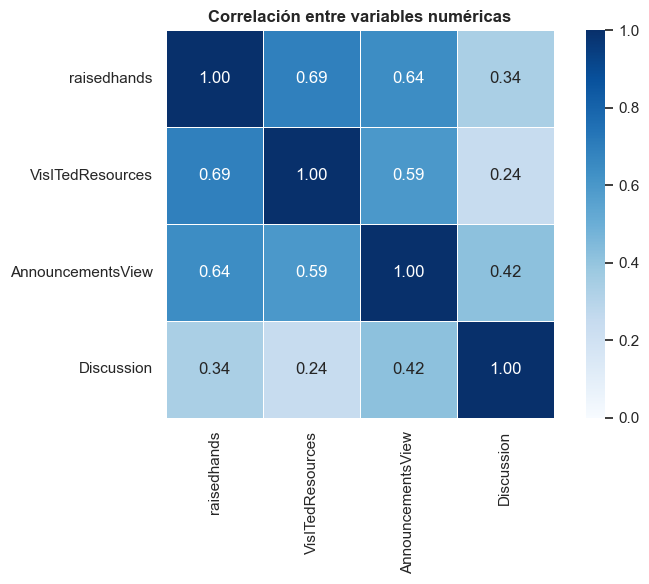

In [36]:
# Seleccionamos únicamente las variables numéricas originales.
numericas = df.select_dtypes(include="number")

# Calculamos la correlación por pares.
corr = numericas.corr()

plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5
)

ax.set_title("Correlación entre variables numéricas", weight="bold")
plt.tight_layout()
plt.show()


### Paso 7.2 · Ordenar las relaciones sin repetir pares

🎯 La matriz muestra cada relación dos veces. El siguiente código conserva solo la mitad superior, elimina la diagonal y ordena los pares de mayor a menor correlación absoluta.


In [24]:
# Creamos una máscara triangular para no repetir relaciones.
mascara_superior = np.triu(np.ones(corr.shape, dtype=bool), k=1)

# Convertimos la mitad superior en una lista ordenada de pares.
pares_correlacion = (
    corr.where(mascara_superior)
        .stack()
        .rename("correlacion")
        .reset_index()
        .rename(columns={"level_0": "variable_1", "level_1": "variable_2"})
)

pares_correlacion["magnitud"] = pares_correlacion["correlacion"].abs()
display(pares_correlacion.sort_values("magnitud", ascending=False).head(6).round(2))


,variable_1,variable_2,correlacion,magnitud
0,raisedhands,VisITedResources,0.69,0.69
1,raisedhands,AnnouncementsView,0.64,0.64
3,VisITedResources,AnnouncementsView,0.59,0.59
5,AnnouncementsView,Discussion,0.42,0.42
2,raisedhands,Discussion,0.34,0.34
4,VisITedResources,Discussion,0.24,0.24


<details>
<summary><strong>Lectura orientativa con el archivo original</strong></summary>

La correlación entre <code>raisedhands</code> y <code>VisITedResources</code> es aproximadamente **0,69**, una asociación lineal positiva. No permite afirmar que una conducta produzca la otra ni que alguna cause el rendimiento.
</details>

✍️ **Escribe una interpretación que incluya:** las dos variables, el coeficiente, la dirección, la intensidad aproximada y una advertencia sobre causalidad.


## 8. Resolver y comunicar el reto (25 min)

### Paso 8.1 · Elegir una pregunta

Selecciona una opción:

1. ¿Cómo cambia la participación según el nivel de rendimiento?
2. ¿Cómo se distribuye el rendimiento según las ausencias?
3. ¿Qué relación existe entre visitas a recursos y participación?
4. Formula una pregunta propia y justifica por qué puede responderse con estas variables.

### Paso 8.2 · Planificar antes de programar

| Elemento | Tu decisión |
|---|---|
| Pregunta | |
| Variable(s) | |
| Tipo de cada variable | |
| Tabla o cálculo | |
| Gráfico adecuado | |
| Posible limitación | |

> Una buena pregunta nombra variables y población; evita anticipar la respuesta.


### Paso 8.3 · Construir la evidencia

▶️ Completa la celda. El ejemplo está comentado para que no se ejecute hasta que lo adaptes.


In [25]:
# RETO: escribe aquí tu análisis.

# 1. Cálculo o tabla de respaldo
# evidencia = df.groupby("Class")["raisedhands"].median().reindex(orden_clase)
# display(evidencia)

# 2. Primera visualización
# plt.figure(figsize=(8, 5))
# sns.boxplot(data=df, x="Class", y="raisedhands", order=orden_clase)
# plt.title("Escribe un título informativo")
# plt.xlabel("Escribe el nombre del eje X")
# plt.ylabel("Escribe el nombre del eje Y")
# plt.tight_layout()
# plt.show()

# 3. Segunda visualización complementaria
# El segundo gráfico debe añadir información, no repetir exactamente el primero.


### Paso 8.4 · Redactar un hallazgo completo

Utiliza la estructura **OELR**:

1. **Observación:** describe el patrón sin explicar causas.
2. **Evidencia:** incluye una cifra, tabla o elemento visible del gráfico.
3. **Limitación:** aclara qué no puede concluirse.
4. **Recomendación:** propone una acción prudente y proporcional a la evidencia.

#### Plantilla

> **Observación:** En este conjunto de datos, ____________________________________.  
> **Evidencia:** El grupo/coeficiente/porcentaje _________________________________.  
> **Limitación:** Este resultado no permite afirmar ______________________________.  
> **Recomendación:** Sería razonable ____________________________________________.

⚠️ Sustituye expresiones vagas como “se ve que” por cifras concretas.


### Paso 8.5 · Lista de verificación antes de entregar

- [ ] Mi código se ejecuta de arriba hacia abajo sin errores.
- [ ] Cada gráfico tiene título y ejes comprensibles.
- [ ] Elegí un gráfico adecuado para los tipos de variables.
- [ ] Mis tres hallazgos incluyen cifras o evidencia visible.
- [ ] Distinguí asociación de causalidad.
- [ ] Mencioné al menos una limitación.
- [ ] Mi recomendación no excede lo que los datos permiten afirmar.

### Rúbrica

| Criterio | Peso |
|---|---:|
| Código correcto y reproducible | 25 % |
| Gráficos adecuados y legibles | 25 % |
| Interpretación sustentada | 35 % |
| Limitación y recomendación responsable | 15 % |


## 9. Cierre y autoevaluación (10 min)

Responde sin ejecutar código:

1. ¿Qué diferencia existe entre <code>info()</code> y <code>describe()</code>?
2. ¿Cuándo usarías un gráfico de barras, histograma, boxplot o dispersión?
3. ¿Por qué una correlación no demuestra causalidad?
4. ¿Qué decisión de limpieza evitamos tomar automáticamente y por qué?
5. ¿Qué dato adicional pedirías a la institución para comprender mejor el rendimiento?

### Ticket de salida

- **Lo más importante que aprendí:** ____________________________________________
- **Una duda que todavía tengo:** ______________________________________________
- **Una afirmación que ahora redactaría con más cuidado:** ______________________


<details>
<summary><strong>Guía breve para contrastar la autoevaluación</strong></summary>

1. <code>info()</code> explica estructura, tipos y valores no nulos; <code>describe()</code> resume distribuciones.
2. Barras: categorías; histograma: distribución numérica; boxplot: comparar una variable numérica entre grupos; dispersión: relación entre dos variables numéricas.
3. Una asociación puede deberse a variables omitidas, selección, temporalidad u otros mecanismos.
4. No eliminamos duplicados automáticamente porque no existe un identificador único que permita confirmar que sean errores.
5. Son respuestas válidas, entre otras: calificación exacta, identificador anónimo, fecha, historial académico, modalidad, acceso tecnológico o intervención docente.
</details>

---

### Mensaje final

Un buen EDA no termina con “encontré un patrón”. Termina con una afirmación más precisa: **qué observé, con qué evidencia, bajo qué límites y cuál sería el siguiente análisis responsable**.
